# Which LLM wrote this text? Notebook 2: handcrafted stylometric features

**Task.** Given a text, predict which of 18 language models generated it (~150 prompts, each answered by every model).
On Kaggle the notebook is re-run on a **hidden** test set, so all feature extraction lives inside the scikit-learn pipelines and only depends on the raw text.

**Where notebook 1 stopped.** Word TF-IDF + logistic regression reaches ~0.31 balanced accuracy in cross-validation (~0.35 on the validation set), and nothing we tried on the classifier side (regularisation, SVM) moved that number. TF-IDF n-grams mostly encode *what a text is about*, while the 18 texts of a prompt share the same topic.

**Idea of this notebook.** Add a small set of dense features describing *how* a text is written: sentence and word lengths, lexical diversity, character-class ratios, and one count per punctuation character.
These few dozen dense features are tiny compared to the ~15k sparse n-gram features, so they should not make overfitting worse by themselves.

**Protocol (identical to notebook 1, so the numbers are directly comparable).**
- Metric: balanced accuracy (chance level = 1/18 ≈ 0.056).
- Same seed, same prompt-grouped train / validation split, same 5-fold grouped CV on the training part only.
- Reference from notebook 1: word TF-IDF + logistic regression (`C=1`) → CV ≈ 0.312, validation ≈ 0.348.

In [26]:
import re
import string
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, balanced_accuracy_score, confusion_matrix
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict, cross_val_score
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42

## 1. Data and train / validation split

In [27]:
from pathlib import Path

# On Kaggle the data lives under /kaggle/input; on Colab / locally we fall back to ./data
kaggle_train = next(Path("/kaggle/input").rglob("train.csv"), None) if Path("/kaggle/input").exists() else None
DATA_DIR = kaggle_train.parent if kaggle_train else Path("data")
OUTPUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")

train_df = pd.read_csv(DATA_DIR / "train.csv")  # columns: id, prompt_id, text, model
test_df = pd.read_csv(DATA_DIR / "test.csv")    # same columns without `model`

In [28]:
# Same split as notebook 1: 20% of the prompts held out, all 18 completions of a prompt stay together.
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, val_idx = next(splitter.split(train_df, train_df["model"], groups=train_df["prompt_id"]))

tr_df = train_df.iloc[train_idx].reset_index(drop=True)
val_df = train_df.iloc[val_idx].reset_index(drop=True)

assert set(tr_df["prompt_id"]).isdisjoint(val_df["prompt_id"]), "prompt leakage between train and val"
print(f"train: {len(tr_df)} texts, {tr_df['prompt_id'].nunique()} prompts")
print(f"val  : {len(val_df)} texts, {val_df['prompt_id'].nunique()} prompts")

train: 2159 texts, 120 prompts
val  : 540 texts, 30 prompts


## 2. What do the texts look like?

Before choosing features, check which kinds of formatting actually exist in the data.

In [29]:
text = train_df["text"]
print("share of texts containing a line break          :", text.str.contains("\n").mean())
print("share of texts containing markdown (** or #)    :", text.str.contains(r"\*\*|^#", regex=True).mean())
print("share of texts with leading / trailing whitespace:", (text != text.str.strip()).mean())

share of texts containing a line break          : 0.0
share of texts containing markdown (** or #)    : 0.0
share of texts with leading / trailing whitespace: 0.0


All three shares are 0: **every text is plain prose on a single line**, with no paragraphs, bullet points, headers or bold text.
Layout features (number of lines or paragraphs, bullets, markdown markers, trailing spaces...) would therefore be constant and carry no information, so they are not used.
What remains to describe a text is its sentences, its words and its punctuation.

## 3. Stylometric features

`StylometricFeatures` turns raw texts into a dense matrix with two groups of columns:

| Group | Features |
|---|---|
| Length and vocabulary | number of words and sentences; mean / std / max sentence length (in words); mean word length; type-token ratio (distinct words / words) |
| Character classes | share of uppercase letters, digits, whitespace and non-ASCII characters |
| Punctuation | **one count per punctuation character** (ASCII punctuation plus typographic characters such as — – … “ ” ‘ ’). A character is kept only if it appears in at least `min_punct_docs` training texts, so the matrix contains no empty columns. |

Sentences are split with a simple regular expression (after `.`, `!`, `?`) so that the notebook does not depend on NLTK data being downloadable on Kaggle.

In [30]:
PUNCTUATION_CANDIDATES = list(string.punctuation) + list("—–…“”‘’«»•·→")

WORD_RE = re.compile(r"\w+")
SENTENCE_SPLIT_RE = re.compile(r"(?<=[.!?])\s+")

# Features that are already ratios; every other feature is a count or a length (log-transformed, see below)
RATIO_FEATURES = {"type_token_ratio", "upper_ratio", "digit_ratio", "space_ratio", "non_ascii_ratio"}


def basic_features(text):
    """Length / vocabulary / character-class features of one text (ordered dict)."""
    words = WORD_RE.findall(text)
    sentences = [s for s in SENTENCE_SPLIT_RE.split(text.strip()) if s.strip()]
    sentence_lens = [len(WORD_RE.findall(s)) for s in sentences] or [0]
    n_chars = max(len(text), 1)

    return {
        "n_words": len(words),
        "n_sentences": len(sentences),
        "avg_sentence_len": float(np.mean(sentence_lens)),
        "std_sentence_len": float(np.std(sentence_lens)),
        "max_sentence_len": max(sentence_lens),
        "avg_word_len": float(np.mean([len(w) for w in words])) if words else 0.0,
        "type_token_ratio": len({w.lower() for w in words}) / max(len(words), 1),
        "upper_ratio": sum(c.isupper() for c in text) / n_chars,
        "digit_ratio": sum(c.isdigit() for c in text) / n_chars,
        "space_ratio": sum(c.isspace() for c in text) / n_chars,
        "non_ascii_ratio": sum(ord(c) > 127 for c in text) / n_chars,
    }


class StylometricFeatures(BaseEstimator, TransformerMixin):
    """Raw texts -> dense matrix of stylometric features.

    fit() only decides which punctuation characters get a column (those present in at least
    `min_punct_docs` texts); it never looks at the labels. Because the transformer lives inside the
    Pipeline, this choice is re-made on the training folds only.

    With log_counts=True, counts and lengths go through log1p because they are heavy-tailed;
    ratios are left untouched.
    """

    def __init__(self, log_counts=True, min_punct_docs=20):
        self.log_counts = log_counts
        self.min_punct_docs = min_punct_docs

    @staticmethod
    def _clean(t):
        return "" if pd.isna(t) else str(t)

    def fit(self, X, y=None):
        texts = [self._clean(t) for t in X]
        doc_freq = {p: sum(p in t for t in texts) for p in PUNCTUATION_CANDIDATES}
        self.punct_chars_ = [p for p in PUNCTUATION_CANDIDATES if doc_freq[p] >= self.min_punct_docs]
        self.feature_names_ = list(basic_features("")) + [f"p[{p}]" for p in self.punct_chars_]
        return self

    def transform(self, X):
        rows = []
        for t in X:
            t = self._clean(t)
            rows.append(list(basic_features(t).values()) + [t.count(p) for p in self.punct_chars_])
        M = np.array(rows, dtype=float)
        if self.log_counts:
            count_cols = [i for i, name in enumerate(self.feature_names_) if name not in RATIO_FEATURES]
            M[:, count_cols] = np.log1p(M[:, count_cols])
        return M

    def get_feature_names_out(self, input_features=None):
        return np.array(self.feature_names_)


eda_stylo = StylometricFeatures(log_counts=False).fit(tr_df["text"])   # raw values, for inspection only
print(f"{len(eda_stylo.feature_names_)} features = {len(basic_features(''))} basic + {len(eda_stylo.punct_chars_)} punctuation columns")
print("punctuation kept:", " ".join(eda_stylo.punct_chars_))

25 features = 11 basic + 14 punctuation columns
punctuation kept: " ' ( ) , - . : ; ? — “ ” ’


## 4. A first look at the features

Two quick checks on whether these features differ between models: the average of a few interpretable features per model, and a ranking of all features by their ANOVA F-statistic (between-model variance / within-model variance, computed on the training split only).

In [31]:
style_df = pd.DataFrame(eda_stylo.transform(train_df["text"]), columns=eda_stylo.get_feature_names_out())
style_df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
n_words,2699.0,116.694,59.093,37.000,66.000,103.000,161.000,279.000
n_sentences,2699.0,4.844,2.157,1.000,3.000,5.000,6.000,14.000
avg_sentence_len,2699.0,24.559,10.684,9.200,20.000,23.333,27.000,226.000
std_sentence_len,2699.0,6.057,3.496,0.000,3.718,5.629,7.864,41.500
max_sentence_len,2699.0,33.205,12.560,14.000,26.000,31.000,38.000,226.000
avg_word_len,2699.0,5.385,0.534,3.840,5.013,5.338,5.713,7.371
type_token_ratio,2699.0,0.819,0.084,0.492,0.760,0.819,0.886,1.000
upper_ratio,2699.0,0.009,0.004,0.002,0.007,0.008,0.011,0.039
digit_ratio,2699.0,0.001,0.002,0.000,0.000,0.000,0.000,0.023
space_ratio,2699.0,0.150,0.012,0.110,0.141,0.150,0.158,0.187


In [32]:
# Average of a few interpretable features, per model (only columns that exist)
wanted = ["n_words", "avg_sentence_len", "avg_word_len", "type_token_ratio", "p[—]", "p[’]", "p[:]", "p[;]"]
cols = [c for c in wanted if c in style_df.columns]
style_df[cols].groupby(train_df["model"].values).mean().round(2)

,n_words,avg_sentence_len,avg_word_len,type_token_ratio,p[—],p[’],p[:],p[;]
claude-fable-5,115.74,24.89,5.24,0.81,1.50,0.00,0.76,0.46
claude-opus-4-6,117.40,27.85,5.52,0.81,1.30,0.00,0.46,0.15
claude-opus-4-8,126.32,24.44,5.34,0.80,0.97,0.00,0.56,0.26
claude-opus-5,125.87,24.38,4.96,0.78,1.50,0.00,0.96,0.66
claude-sonnet-5,123.95,27.14,5.50,0.82,1.26,0.00,0.65,0.27
gemini-3.1-pro-preview,119.71,20.32,5.48,0.80,0.00,0.07,0.17,0.21
gemini-3.6-flash,111.85,24.83,5.68,0.83,0.00,0.23,0.21,0.23
gemini-3.7-flash,118.04,24.06,5.89,0.84,0.01,0.39,0.23,0.25
gemini-3.8-flash,101.33,22.88,5.86,0.86,0.00,0.30,0.19,0.29
glm-5.3,113.69,24.08,5.22,0.81,1.62,0.00,0.84,0.45


In [33]:
# Which features separate the 18 models best? (training split only, same transformation as in the models)
stylo = StylometricFeatures().fit(tr_df["text"])
X_style_tr = stylo.transform(tr_df["text"])

with warnings.catch_warnings():
    warnings.simplefilter("ignore")        # a constant column would give an undefined F-statistic
    f_stat, _ = f_classif(X_style_tr, tr_df["model"])

ranking = pd.Series(np.nan_to_num(f_stat), index=stylo.get_feature_names_out(), name="F-statistic")
ranking.sort_values(ascending=False).head(15).round(1).to_frame()

,F-statistic
p[—],92.3
p['],55.4
p[’],36.5
avg_word_len,29.8
p[:],25.5
non_ascii_ratio,22.2
space_ratio,19.7
p[;],16.5
p[-],9.7
avg_sentence_len,9.7


## 5. Models

Compared with exactly the same protocol:
1. **Reference**: word TF-IDF + logistic regression (notebook 1).
2. **Stylometric features only**, with a linear model and with gradient boosting (trees can capture interactions between features and do not need scaling). This measures how much signal style carries *on its own*.
3. **TF-IDF + stylometric features**, concatenated into one feature matrix.

For the concatenation, the stylometric block is standardised (zero mean, unit variance) and multiplied by a **weight**. This matters: TF-IDF rows have unit L2 norm spread over thousands of columns (each value is tiny), whereas standardised features have unit variance each. Without a weight, the dense block would dominate the logistic regression and be barely regularised. The weight is therefore swept.

In [34]:
def evaluate(pipe):
    """Grouped CV on the training split + train / validation scores for one pipeline."""
    cv_scores = cross_val_score(
        pipe, tr_df["text"], tr_df["model"],
        groups=tr_df["prompt_id"], cv=cv,
        scoring="balanced_accuracy", n_jobs=-1,
    )
    pipe.fit(tr_df["text"], tr_df["model"])
    train_score = balanced_accuracy_score(tr_df["model"], pipe.predict(tr_df["text"]))
    val_score = balanced_accuracy_score(val_df["model"], pipe.predict(val_df["text"]))
    return {
        "cv": cv_scores.mean(),
        "cv std": cv_scores.std(),
        "train": train_score,
        "val": val_score,
        "train - val gap": train_score - val_score,
    }


cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)   # same CV as notebook 1

# Word TF-IDF: identical settings to notebook 1
word_tfidf = TfidfVectorizer(
    token_pattern=r"(?u)\w+|[^\w\s]",  # words and individual punctuation marks
    ngram_range=(1, 2),
    lowercase=False,
    sublinear_tf=True,
    min_df=5,
)


def make_combined_pipeline(stylo_weight, C=1.0):
    """[word TF-IDF | weight * standardised stylometric features] -> logistic regression."""
    features = FeatureUnion(
        [
            ("tfidf", clone(word_tfidf)),
            ("stylo", Pipeline([("extract", StylometricFeatures()), ("scale", StandardScaler())])),
        ],
        transformer_weights={"tfidf": 1.0, "stylo": stylo_weight},
    )
    return Pipeline([("features", features), ("clf", LogisticRegression(C=C, max_iter=2000))])


experiments = {
    "word TF-IDF + LR (reference)": Pipeline([
        ("tfidf", clone(word_tfidf)),
        ("clf", LogisticRegression(C=1.0, max_iter=2000)),
    ]),
    "stylometric only + LR": Pipeline([
        ("stylo", StylometricFeatures()),
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(C=1.0, max_iter=2000)),
    ]),
    "stylometric only + HistGradientBoosting": Pipeline([
        ("stylo", StylometricFeatures(log_counts=False)),   # trees are invariant to monotone transforms
        ("clf", HistGradientBoostingClassifier(
            max_iter=200, learning_rate=0.05, max_depth=3, l2_regularization=1.0, random_state=SEED)),
    ]),
}
for w in [0.03, 0.1, 0.3, 1.0]:
    experiments[f"TF-IDF + stylometric (weight={w}) + LR"] = make_combined_pipeline(w)

results = pd.DataFrame({name: evaluate(pipe) for name, pipe in experiments.items()}).T
results = results.sort_values("cv", ascending=False)
results.round(4)

#better with tfidf+stylometric but the change is not that big compared with tfidf alone -> we have to go see transformers

,cv,cv std,train,val,train - val gap
TF-IDF + stylometric (weight=0.03) + LR,0.3269,0.0080,0.9926,0.3389,0.6537
TF-IDF + stylometric (weight=0.1) + LR,0.3218,0.0149,0.8818,0.3500,0.5318
word TF-IDF + LR (reference),0.3121,0.0076,0.9995,0.3481,0.6514
TF-IDF + stylometric (weight=0.3) + LR,0.3038,0.0137,0.7438,0.3093,0.4346
TF-IDF + stylometric (weight=1.0) + LR,0.2954,0.0117,0.6919,0.3037,0.3882
stylometric only + LR,0.2709,0.0169,0.3223,0.2889,0.0334
stylometric only + HistGradientBoosting,0.2209,0.0166,0.7661,0.2463,0.5198


**How to read this table.**
- Compare every row to the reference: the question is whether `cv` (and `val`) go up by more than the `cv std`, and not only on the validation set. The validation set only contains ~30 prompts, so differences of ~0.02 in `val` are within noise.
- The *stylometric only* rows tell how much of the signal comes from style alone. Their train / validation gap is also a sanity check that a few dozen dense features do not overfit the way 15k n-grams do.
- The weight sweep shows how much the dense block should count relative to the n-grams. The best weight is the one with the best `cv`, not the best `val`.

## 6. Final model and Kaggle submission

The pipeline with the best CV score (training split only, so the validation set stays an untouched check) is refitted on **all** labelled data and used to predict the test set.
The submission is written as `submission.parquet` with the same columns as the competition's `sample_submission.parquet`. It is produced **before** the error analysis so that a failure in a later, purely diagnostic cell can never prevent the file from being written.

In [35]:
best_name = results["cv"].astype(float).idxmax()
print(f"Selected: {best_name}")

final_model = clone(experiments[best_name])              # fresh, unfitted copy
final_model.fit(train_df["text"], train_df["model"])
test_pred = final_model.predict(test_df["text"])

# Build the submission with the same columns as sample_submission.parquet
sample_path = DATA_DIR / "sample_submission.parquet"
if sample_path.exists():
    sample_sub = pd.read_parquet(sample_path)
    id_col = "id" if "id" in sample_sub.columns else sample_sub.columns[0]
    label_cols = [c for c in sample_sub.columns if c != id_col]
    assert len(label_cols) == 1, f"Unexpected sample_submission format: {list(sample_sub.columns)}"
    label_col = label_cols[0]
    assert not pd.api.types.is_numeric_dtype(sample_sub[label_col]), (
        f"'{label_col}' is numeric in the sample submission: it probably expects class indices "
        "or probabilities, not model names. Check the competition's evaluation page."
    )
else:
    id_col, label_col = "id", "model"

submission = pd.DataFrame({id_col: test_df["id"], label_col: test_pred})

# Sanity checks (sizes come from the test file actually loaded, not hard-coded: the scoring test set is hidden)
assert len(submission) == len(test_df)
assert submission[id_col].is_unique
assert set(submission[label_col]) <= set(train_df["model"])

submission_path = OUTPUT_DIR / "submission.parquet"
submission.to_parquet(submission_path, index=False)
print(f"Written: {submission_path} ({len(submission)} rows)")
submission.head()

#score: 0.334 -> 0.358

Selected: TF-IDF + stylometric (weight=0.03) + LR
Written: /kaggle/working/submission.parquet (3 rows)


,id,model
0,00353fb1c541,gemini-3.8-flash
1,005f5a9a6139,gpt-5.6-terra
2,0062a53d5487,gemini-3.7-flash


## 7. Error analysis: confusion matrix (prompt-grouped cross-validation)

Out-of-fold predictions on the whole labelled set: every text is predicted by a model that has never seen its prompt. Each row is normalised, so a cell is the share of a model's texts predicted as the column model.

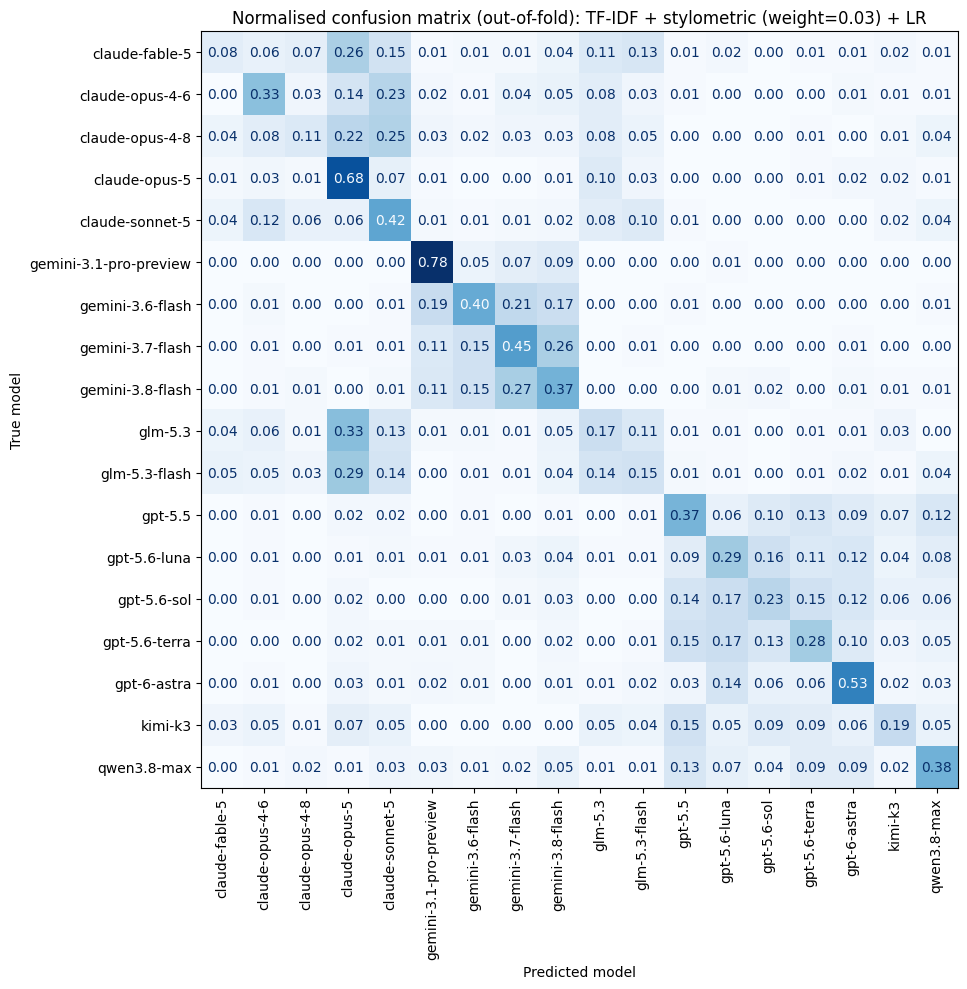

In [38]:
oof_pred = cross_val_predict(
    clone(final_model),
    train_df["text"],
    train_df["model"],
    groups=train_df["prompt_id"],
    cv=cv,
    n_jobs=-1,
)

labels = sorted(train_df["model"].unique())
cm = confusion_matrix(train_df["model"], oof_pred, labels=labels, normalize="true")

fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(
    ax=ax, cmap="Blues", xticks_rotation=90, values_format=".2f", colorbar=False
)
ax.set_title(f"Normalised confusion matrix (out-of-fold): {best_name}")
ax.set_xlabel("Predicted model")
ax.set_ylabel("True model")
plt.tight_layout()
plt.show()

#Better recognition of claude(doesn't confuse it with glm as much as before)

## 8. Conclusion

- **The texts are plain single-line prose** (no line breaks, paragraphs or markdown), so all layout features are constant and were dropped. Only sentence, word and punctuation statistics remain.
- **Style alone carries real signal.** The stylometric-only logistic regression is well above chance (0.056) and has a very small train / validation gap, unlike the n-gram models, which fit the training set almost perfectly.
- **Adding it to TF-IDF helps little.** The gain over the reference is small compared to the CV standard deviation, and the dense block has to be strongly down-weighted: larger weights make the score worse (see the table in section 5).
- **Gradient boosting does not beat logistic regression** on these features, so there is no strong non-linear structure to exploit with so few samples.
- **Most remaining confusions are between versions of the same family** (see the confusion matrix), which are hard to separate with surface statistics.

**Next steps**
- Pretrained transformers (contextual embeddings, then fine-tuning), which can capture style beyond local n-grams (notebook 3).
- Remove the topic from the dense features by subtracting, for each prompt, the mean feature vector of its texts (only possible if the hidden test keeps several texts per prompt).